# Module 6 Lab 1: Query Like an Analyst
## Step 1: Load the CSVs and build the database
Load both CSVs with pandas, connect to a new store.db, and pour each DataFrame in as tables named orders and customers

In [2]:
import pandas as pd
import sqlite3

# loading csv
orders_df = pd.read_csv("store_orders.csv")
customers_df = pd.read_csv("store_customers.csv")

#connecting to database
con = sqlite3.connect("store.db")

#pouring df into db as new table
orders_df.to_sql("orders", con, index=False)
customers_df.to_sql("customers", con, index=False)

#list tables
pd.read_sql("SELECT name FROM sqlite_master",con)

,name
0,orders
1,customers


## Step 2: First look
Query the first 5 rows of orders

In [4]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


## Step 3: Filter and sort
Write one query returning all orders over 100 dollars, sorted by amount from highest to lowest

In [14]:
# querying all orders over $100
query = """
SELECT *
FROM orders
WHERE amount > 100 
ORDER BY amount DESC
"""
# print result
result = pd.read_sql(query,con)
print(result)

    order_id  customer_id  product     category  amount  order_date
0       5153           20     dock  electronics  499.00  2026-05-25
1       5140           30  headset  electronics  295.36  2026-05-26
2       5047          901  headset  electronics  293.79  2026-05-15
3       5150          903  monitor  electronics  293.35  2026-06-06
4       5014            6  monitor  electronics  287.83  2026-05-22
..       ...          ...      ...          ...     ...         ...
79      5107           38    shelf    furniture  110.31  2026-05-17
80      5046           13    shelf    furniture  108.47  2026-05-28
81      5009           14    chair    furniture  107.20  2026-05-24
82      5007           36     dock  electronics  103.77  2026-05-21
83      5023            9     desk    furniture  100.27  2026-06-05

[84 rows x 6 columns]


## Step 4: Aggregate by category
One query: for each product category, the number of orders and the average amount, named with AS, sorted by average amount descending

In [16]:
query = """
SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount
FROM orders 
GROUP BY category
ORDER BY avg_amount DESC
"""
# print result
result = pd.read_sql(query, con)
print(result)

      category   n  avg_amount
0  electronics  60  190.569500
1    furniture  46  146.251522
2       office  51   30.132549
3       snacks  43   14.619767


Electronics earns the most per order.

## Step 5: Join for spend by city
Write the JOIN: total spend per customer city, using the key the data dictionary gives you, sorted by total descending

In [17]:
query = """
SELECT customers.city, SUM(orders.amount) AS total_spend
FROM orders
JOIN customers ON orders.customer_id = customers.customer_id
GROUP BY customers.city
ORDER BY total_spend DESC;
"""
result = pd.read_sql(query, con)
print(result)

           city  total_spend
0   Los Angeles      5862.99
1   Culver City      5316.88
2  Santa Monica      4017.93
3     Inglewood      2718.25
4      Torrance      1037.25
5        Venice       462.36


## Step 6: The row-count audit (markdown cell)
Count the rows of orders and the rows your join produced

In [19]:
# count total orders in original table
query_orders ="SELECT COUNT(*) AS total_orders FROM orders;"
print("Original Orders Count:")
print(pd.read_sql(query_orders, con))

# count rows when tables are joined
query_join= """
SELECT COUNT(*) AS joined_rows
FROM orders
JOIN customers ON orders.customer_id = customers.customer_id;
"""
print("Joined Table Count:")
print(pd.read_sql(query_join, con))

Original Orders Count:
   total_orders
0           200
Joined Table Count:
   joined_rows
0          195


When tables are joined, it will only keep rows that have a match on both tables. This means that 5 orders didn't have a customer_id that matched a customer_id in the customers table, so they were dropped.

## Step 7: Chart a query result
Take your Step 5 result and bar-chart total spend by city, fully labeled with title and units.

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Los Angeles'),
  Text(1, 0, 'Culver City'),
  Text(2, 0, 'Santa Monica'),
  Text(3, 0, 'Inglewood'),
  Text(4, 0, 'Torrance'),
  Text(5, 0, 'Venice')])

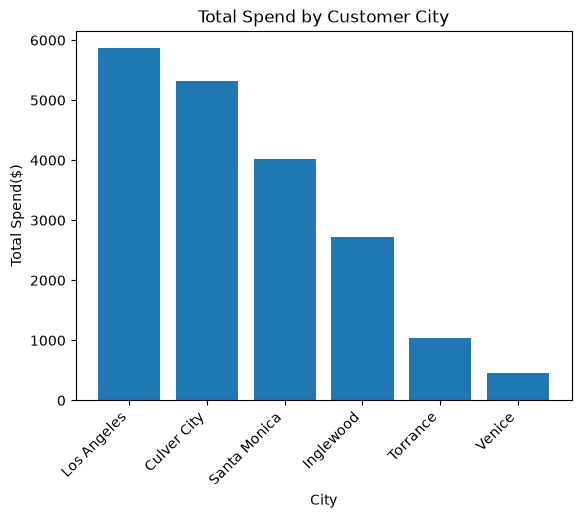

In [22]:
import matplotlib.pyplot as plt

plt.bar(result["city"], result["total_spend"])
plt.title("Total Spend by Customer City")
plt.xlabel("City")
plt.ylabel("Total Spend($)")
plt.xticks(rotation=45, ha="right")

## Step 8: Your own question
What is the average order value for each city, and which city spends the most on averager per order?

In [25]:
query_city_average="""
select customers.city, AVG(orders.amount) AS average_order_value, COUNT(orders.amount) AS total_orders
FROM orders
Join customers ON orders.customer_id = customers.customer_id
GROUP BY customers.city
ORDER BY average_order_value DESC;
"""
result_city_average = pd.read_sql(query_city_average, con)
print(result_city_average)

           city  average_order_value  total_orders
0   Los Angeles           127.456304            46
1     Inglewood           100.675926            27
2  Santa Monica            95.665000            42
3   Culver City            91.670345            58
4      Torrance            74.089286            14
5        Venice            57.795000             8


Los Angeles spends the most on average per order with $127.46. Following is Inglewood with 100.68 and Santa Monica with 95.67.

## Step 9: Ethics note and safe push 
Before sharing these results publicly, I would completely strip all personally identifiable information like customer names and IDs from the dataset. Protecting this data is ethically necessary to prevent privacy breaches and maintain user trust.